# sequential workflows

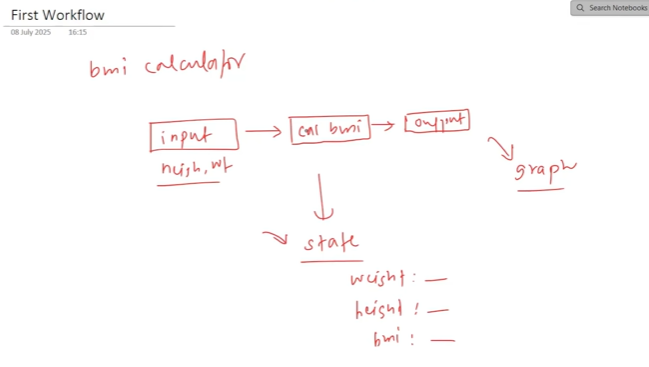

In [17]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [18]:
#define state
class BMI(TypedDict):
    w : float
    h : float
    bmi : float

In [25]:
def calc_bmi(state: BMI) -> BMI:

    weight = state['w']
    height = state['h']

    bmi = weight/(height**2)

    state['bmi'] = round(bmi, 2)

    return state

In [26]:
def label_bmi(state: BMI) -> BMI:

    bmi = state['bmi']

    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 25:
        state["category"] = "Normal"
    elif 25 <= bmi < 30:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obese"

    return state

In [27]:
#define graph

graph = StateGraph(BMI)

graph.add_node('calc_bmi',calc_bmi)
graph.add_node('label_bmi',label_bmi)


graph.add_edge(START,'calc_bmi')
graph.add_edge('calc_bmi','label_bmi')
graph.add_edge('label_bmi',END)

workflow = graph.compile()

In [28]:
initial_state = {'w':45, 'h':1.73}
final_state = workflow.invoke(initial_state)
print(final_state)

{'w': 45, 'h': 1.73, 'bmi': 15.04}


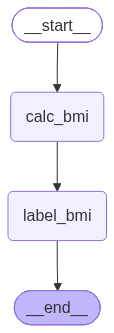

In [29]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

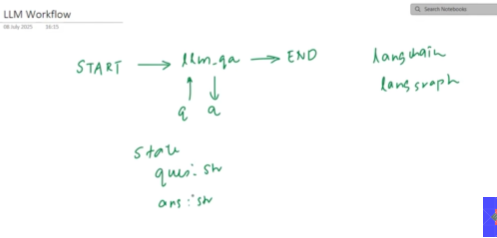

In [76]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from langchain_groq import ChatGroq
from dotenv import load_dotenv

load_dotenv()
model = ChatGroq(model = "openai/gpt-oss-120b")

In [77]:
class QA_LLM(TypedDict):
    ques : str
    ans : str

In [78]:
def llm(state: QA_LLM) -> QA_LLM:

    # extract the question from state
    ques = state['ques']

    # form a prompt
    prompt = f'Answer the following question {ques}'

    # ask that question to the LLM
    ans = model.invoke(prompt).content

    # update the answer in the state
    state['ans'] = ans

    return state    

In [79]:
graph = StateGraph(QA_LLM)

graph.add_node('llm',llm)

graph.add_edge(START,'llm')
graph.add_edge('llm',END)


flow = graph.compile()

In [80]:
initial_state = {'ques':'what is transformers'}
final_state = flow.invoke(initial_state)
print(final_state['ans'])

**Transformers** are a family of neural‑network architectures that have become the dominant approach for a wide range of sequence‑modeling tasks, especially in natural language processing (NLP) but also in vision, audio, reinforcement learning, and more.  

---

## 1. Core Idea

The key innovation of the transformer is the **self‑attention (or scaled dot‑product attention) mechanism**, which lets every element of an input sequence directly attend to (i.e., gather information from) every other element. This replaces the recurrent or convolutional operations used in earlier models and enables:

* **Parallel processing** of all sequence positions (unlike RNNs that must step through time sequentially).  
* **Dynamic, content‑based weighting** of relationships, allowing the model to capture long‑range dependencies efficiently.  

---

## 2. Architecture Overview

A standard transformer (as introduced in *“Attention Is All You Need”* — Vaswani et al., 2017) consists of two main blocks:

| Bl

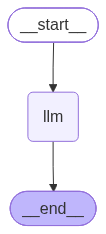

In [81]:
from IPython.display import Image
Image(flow.get_graph().draw_mermaid_png())

In thia

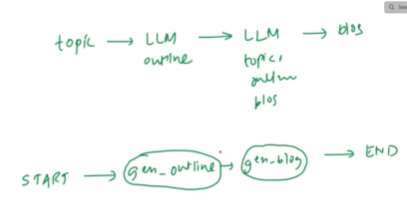